# Supplementary figure: validation RMSE vs number of input features

Feature-count scan used to choose the encoder input size for each modality
(`figure1c` in `training_configuration.py`, reported in Table S4). Base DMM
(`EGFR_MAPK__logobs`) with the central ML hyperparameters, trained on feature
sets selected by recursive feature elimination (RFE; HVGRFE = RFE after a
highly-variable-feature prefilter) of size N = 4 … 4,096, plus the full
post-filter feature set (`all`). Five CV folds, each holding out one cell line
(BT20, HCC1500, HCC2185, MCF7, UACC3199), × 10 random starts.

The x-axis is the number of features that actually enter the encoder, which is
not always N:

* **HVGRFE** (MassSpec, RNAseq) selects from the ~500 most variable features,
  so every N ≥ 512 gives the same 501 inputs; those runs collapse to one point.
* **Multimodal** concatenates N selected features from each of CyTOF, MassSpec
  and RNAseq, i.e. 3N inputs.
* **`all`** is every feature that passes the missing-value filter (no RFE).

Input: `eval/EGFR_MAPK__logobs/dream_cytof/evaluate_all_figure1c.csv`
(from the NEMO evaluation run) and the PEtab measurement table in `data/`.

In [1]:
import sys
from pathlib import Path

# Ensure project root is on sys.path
_project_root = str(
    next(
        (
            _p
            for _p in (Path.cwd(), *Path.cwd().parents)
            if (_p / "common.py").is_file()
        ),
        Path.cwd().parent,
    )
)
if _project_root not in sys.path:
    sys.path.insert(0, _project_root)

import ast
import importlib
import re
import warnings
from typing import Union

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from scipy import stats
from sklearn.impute import KNNImputer

warnings.filterwarnings("ignore")

import figures_paper.figure_config as figure_config
from common import EVALUATE_ALL_CSVS, Wildcards, training_samples, val_samples
from dmm.config_options import Conf
from dmm.feature_selection import load_data, preprocess_mosa_latent
from training_configuration import (
    BEST_FEATURE_SETS,
    CONTEXTS_FEATURES_1C,
    SPLITS_1C,
)
from util import load_petab_base_files

importlib.reload(figure_config)
from figures_paper.figure_config import (
    CONTEXT_COLORS,
    FONTSIZE,
    LW_MEDIUM,
    LW_THICK,
    LW_THIN,
    configure_axis_spines,
    get_context_label,
)

## Configuration

In [2]:
model = "EGFR_MAPK__logobs"
data = "dream_cytof"
figure = "figure1c"

CONTEXT_ORDER = ["cytof_init", "transcriptomics", "proteomics", "multimodal", "MOSA"]
SPLITS = sorted(SPLITS_1C)

# Contexts whose multimodal recipe concatenates N features per modality
# (select_features.build_context_feature_recipe)
MULTIMODAL_PARTS = ["cytof_init", "proteomics", "transcriptomics"]

SCAN_RE = re.compile(r"^(?P<method>HVGRFE|RFE)_(?P<N>\d+)_permute$")


def parse_n(features: str) -> int | None:
    m = SCAN_RE.match(features)
    return int(m["N"]) if m else None

## Candidate features per modality and CV fold

Replicates `select_features.prepare_inputs_for_context` up to the selection
step: pivot of the PEtab measurement table (training lines only) → drop
features with ≥ 30 % missing values (`load_data`) → KNN imputation →
mean-centring → HVG prefilter (`get_hvg`, HVGRFE only).

In [3]:
# get_hvg lives in select_features.py, which runs fire.Fire() at import;
# load just that function so the counts use the pipeline's own code.
_src = (Path(_project_root) / "select_features.py").read_text()
_fn = next(
    n for n in ast.parse(_src).body
    if isinstance(n, ast.FunctionDef) and n.name == "get_hvg"
)
_ns = {"np": np, "pd": pd, "Union": Union}
exec(compile(ast.Module(body=[_fn], type_ignores=[]), "get_hvg", "exec"), _ns)
get_hvg = _ns["get_hvg"]

petab_base_files = load_petab_base_files(Conf(model=model, data=data))
del petab_base_files["condition_table"]
measurements = petab_base_files["measurement_table"]

count_rows = []
for split in SPLITS:
    wc = Wildcards(data, split)
    samples_train, samples_val = training_samples(wc), val_samples(wc)
    for context in ["cytof_init", "proteomics", "transcriptomics"]:
        omics = context in ("proteomics", "transcriptomics")
        if omics:
            raw = measurements[
                (measurements.measurementType == context)
                & (measurements.time == 0)
                & measurements.preequilibrationConditionId.isin(samples_train)
            ].FEATURE_ID.nunique()
        X, *_ = load_data(
            contextualization=context,
            samples=samples_train,
            features=None,
            **petab_base_files,
        )
        X = pd.DataFrame(KNNImputer().fit_transform(X), index=X.index, columns=X.columns)
        X -= X.mean()
        count_rows.append(
            dict(
                context=context,
                samples=split,
                n_train_lines=len(samples_train),
                n_raw=raw if omics else X.shape[1],
                n_all=X.shape[1],
                n_hvg=get_hvg(X).shape[1] if omics else np.nan,
            )
        )
    X_mosa, _, _ = preprocess_mosa_latent(
        Conf(model=model, data=data, context="MOSA", samples=split),
        samples_train,
        samples_val,
    )
    count_rows.append(
        dict(
            context="MOSA",
            samples=split,
            n_train_lines=len(X_mosa),
            n_raw=X_mosa.shape[1],
            n_all=X_mosa.shape[1],
            n_hvg=np.nan,
        )
    )

counts = pd.DataFrame(count_rows).set_index(["context", "samples"]).sort_index()
counts

n_train_lines  n_raw  n_all  n_hvg
context         samples                                     
MOSA            BT20                 45    200    200    NaN
                HCC1500              45    200    200    NaN
                HCC2185              46    200    200    NaN
                MCF7                 45    200    200    NaN
                UACC3199             46    200    200    NaN
cytof_init      BT20                 57     37     37    NaN
                HCC1500              57     37     37    NaN
                HCC2185              57     37     37    NaN
                MCF7                 57     37     37    NaN
                UACC3199             57     37     37    NaN
proteomics      BT20                 57   7874   6179  501.0
                HCC1500              57   7872   6177  501.0
                HCC2185              57   7873   6182  501.0
                MCF7                 57   7874   6187  501.0
                UACC3199             57   7874   6181  501.0
transcriptomics BT20                 57  16562  16562  501.0
                HCC1500              57  16562  16562  501.0
                HCC2185              57  16562  16562  501.0
                MCF7                 57  16562  16562  501.0
                UACC3199             57  16562  16562  501.0

In [4]:
# Raw feature counts over all cell lines in the measurement table, for reference
raw_all_lines = {
    context: measurements[
        (measurements.measurementType == context) & (measurements.time == 0)
    ]
    .groupby("FEATURE_ID")
    .preequilibrationConditionId.nunique()
    for context in ["proteomics", "transcriptomics"]
}
n_lines_all = {
    context: measurements[measurements.measurementType == context]
    .preequilibrationConditionId.nunique()
    for context in raw_all_lines
}
for context, per_feature in raw_all_lines.items():
    print(
        f"{context:16s}: {len(per_feature):,} features in the table, "
        f"{(per_feature == n_lines_all[context]).sum():,} measured in all "
        f"{n_lines_all[context]} lines"
    )
print()
print(
    counts.groupby("context")[["n_train_lines", "n_raw", "n_all", "n_hvg"]]
    .agg(["min", "median", "max"])
    .to_string()
)

proteomics      : 7,877 features in the table, 3,751 measured in all 67 lines
transcriptomics : 16,562 features in the table, 16,562 measured in all 64 lines

                n_train_lines             n_raw                  n_all                  n_hvg              
                          min median max    min   median    max    min   median    max    min median    max
context                                                                                                    
MOSA                       45   45.0  46    200    200.0    200    200    200.0    200    NaN    NaN    NaN
cytof_init                 57   57.0  57     37     37.0     37     37     37.0     37    NaN    NaN    NaN
proteomics                 57   57.0  57   7872   7874.0   7874   6177   6181.0   6187  501.0  501.0  501.0
transcriptomics            57   57.0  57  16562  16562.0  16562  16562  16562.0  16562  501.0  501.0  501.0


## Load scan evaluations

In [5]:
df = pd.read_csv(
    EVALUATE_ALL_CSVS.format(model=model, data=data, filename=f"evaluate_all_{figure}"),
    index_col=0,
)
val = df[(df.dataset == "val") & (df.ref == "DMM") & (df.model == model)].copy()
val["N"] = val["features"].map(parse_n)
val = val[val["N"].notna() | (val["features"] == "all")]


def n_inputs(row) -> int:
    """Number of features that enter the encoder for one run."""
    if row.context == "multimodal":
        return int(
            sum(
                min(row.N, counts.loc[(part, row.samples), "n_hvg"])
                if part != "cytof_init"
                else min(row.N, counts.loc[(part, row.samples), "n_all"])
                for part in MULTIMODAL_PARTS
            )
        )
    c = counts.loc[(row.context, row.samples)]
    if row.features == "all":
        return int(c.n_all)
    if row.features.startswith("HVGRFE"):
        return int(min(row.N, c.n_hvg))
    return int(min(row.N, c.n_all))


val["n_inputs"] = val.apply(n_inputs, axis=1)

# Runs per (context, feature set): expect 5 folds x 10 starts (MOSA: fewer folds,
# since not every held-out line has a MOSA embedding)
expected = {(c, f) for c, f in CONTEXTS_FEATURES_1C}
found = set(map(tuple, val[["context", "features"]].drop_duplicates().values))
print("Configured but missing from the evaluation:", sorted(expected - found) or "none")
runs = val.groupby(["context", "features"]).agg(
    folds=("samples", "nunique"), runs=("rmse", "size"), n_inputs=("n_inputs", "median")
)
print(runs.sort_values(["context", "n_inputs"]).to_string())

Configured but missing from the evaluation: none
                                     folds  runs  n_inputs
context         features                                  
MOSA            RFE_4_permute            3    30       4.0
                RFE_6_permute            3    30       6.0
                RFE_8_permute            3    30       8.0
                RFE_10_permute           3    30      10.0
                RFE_12_permute           3    30      12.0
                RFE_16_permute           3    30      16.0
                RFE_20_permute           3    30      20.0
                RFE_24_permute           3    30      24.0
                RFE_28_permute           3    30      28.0
                RFE_32_permute           3    30      32.0
                RFE_64_permute           3    30      64.0
                RFE_128_permute          3    30     128.0
                all                      3    30     200.0
cytof_init      RFE_4_permute            5    50       4.0
       

In [6]:
# Feature sets that resolve to the same inputs (HVGRFE N >= 512 -> 501 HVGs)
# must give the same result; keep the smallest N of each such group.
dup = (
    val.groupby(["context", "samples", "n_inputs", "job"])
    .agg(n_sets=("features", "nunique"), spread=("rmse", lambda x: x.max() - x.min()))
    .query("n_sets > 1")
)
print(f"{len(dup)} (context, fold, n_inputs, start) groups with >1 feature set; "
      f"max RMSE spread within a group: {dup.spread.max() if len(dup) else 0:.2e}")

keep = (
    val.assign(_order=val["N"].fillna(np.inf))
    .sort_values("_order")
    .groupby(["context", "n_inputs"])["features"]
    .first()
)
val = val.merge(keep.rename("keep").reset_index(), on=["context", "n_inputs"])
val = val[val["features"] == val["keep"]].drop(columns="keep")

100 (context, fold, n_inputs, start) groups with >1 feature set; max RMSE spread within a group: 0.00e+00


## Aggregate

Median over the 10 random starts within each fold, then mean ± SEM over folds.
Panel B uses the paired, per-fold difference to the selected feature-set size.

In [7]:
per_fold = (
    val.groupby(["context", "features", "N", "n_inputs", "samples"], dropna=False)
    .rmse.median()
    .reset_index()
)

selected = per_fold[
    per_fold.apply(lambda r: r.features == BEST_FEATURE_SETS[r.context], axis=1)
].set_index(["context", "samples"]).rmse
per_fold["delta"] = per_fold.rmse - per_fold.set_index(["context", "samples"]).index.map(selected)

# x position per (context, feature set): "all" for MassSpec varies by a few
# features across folds, so use the median count
summary = (
    per_fold.groupby(["context", "features"])
    .agg(
        n_inputs=("n_inputs", "median"),
        N=("N", "first"),
        rmse_mean=("rmse", "mean"),
        rmse_sem=("rmse", "sem"),
        delta_mean=("delta", "mean"),
        delta_sem=("delta", "sem"),
        folds=("rmse", "size"),
    )
    .reset_index()
    .sort_values(["context", "n_inputs"])
)
summary["is_selected"] = summary.apply(
    lambda r: r.features == BEST_FEATURE_SETS[r.context], axis=1
)
summary["is_all"] = summary.features == "all"

## Plot

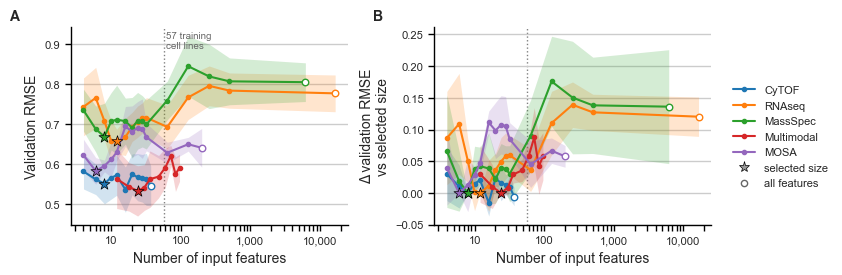

In [8]:
N_TRAIN_LINES = int(counts.n_train_lines.loc[["cytof_init"]].iloc[0])

fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.8), sharex=True)

for ax, (y, yerr, ylabel) in zip(
    axes,
    [
        ("rmse_mean", "rmse_sem", "Validation RMSE"),
        ("delta_mean", "delta_sem", "Δ validation RMSE\nvs selected size"),
    ],
):
    for context in CONTEXT_ORDER:
        s = summary[summary.context == context].sort_values("n_inputs")
        if s.empty:
            continue
        color = CONTEXT_COLORS[get_context_label(context)]
        ax.fill_between(
            s.n_inputs, s[y] - s[yerr], s[y] + s[yerr], color=color, alpha=0.2, lw=0
        )
        ax.plot(
            s.n_inputs, s[y], color=color, lw=LW_THICK, marker="o", ms=3,
            label=get_context_label(context),
        )
        a = s[s.is_all]
        ax.scatter(a.n_inputs, a[y], s=22, facecolor="white", edgecolor=color,
                   linewidth=LW_MEDIUM, zorder=4)
        b = s[s.is_selected]
        ax.scatter(b.n_inputs, b[y], s=70, marker="*", facecolor=color,
                   edgecolor="black", linewidth=LW_THIN, zorder=5)

    ax.axvline(N_TRAIN_LINES, color="0.5", ls=":", lw=LW_MEDIUM, zorder=0)
    ax.set_xscale("log")
    ax.xaxis.set_major_locator(mticker.LogLocator(base=10))
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.set_xlabel("Number of input features")
    ax.set_ylabel(ylabel)
    configure_axis_spines(ax)

axes[1].axhline(0, color="black", lw=LW_THIN, zorder=0)
axes[0].text(
    N_TRAIN_LINES * 1.08, 0.98, f"{N_TRAIN_LINES} training\ncell lines",
    transform=axes[0].get_xaxis_transform(), va="top", fontsize=FONTSIZE - 1, color="0.4",
)

handles, labels = axes[0].get_legend_handles_labels()
handles += [
    Line2D([], [], ls="", marker="*", ms=8, mfc="0.6", mec="black", mew=LW_THIN),
    Line2D([], [], ls="", marker="o", ms=4.5, mfc="white", mec="0.4", mew=LW_MEDIUM),
]
labels += ["selected size", "all features"]
fig.legend(handles, labels, loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False)
for ax, letter in zip(axes, "AB"):
    ax.text(-0.22, 1.02, letter, transform=ax.transAxes, fontweight="bold",
            fontsize=FONTSIZE + 2, va="bottom")
fig.tight_layout()
fig.savefig("figure_S_feature_count_scan.pdf", bbox_inches="tight")
fig.savefig("figure_S_feature_count_scan.png", dpi=300, bbox_inches="tight")
plt.show()

## Checks for the Methods / response text

* Size with the lowest mean validation RMSE per modality, and how far it is
  from the selected size.
* RMSE at the largest feature set relative to the best one, with the number of
  folds in which the largest set is worse than the selected one.
* Spearman correlation between log(number of inputs) and mean RMSE across all
  tested sizes.

In [9]:
rows = []
for context in CONTEXT_ORDER:
    s = summary[summary.context == context].sort_values("n_inputs")
    if s.empty:
        continue
    best = s.loc[s.rmse_mean.idxmin()]
    sel = s[s.is_selected].iloc[0]
    largest = s.iloc[-1]
    pf_largest = per_fold[(per_fold.context == context) & (per_fold.features == largest.features)]
    rho, p = stats.spearmanr(np.log(s.n_inputs), s.rmse_mean)
    rows.append(
        dict(
            modality=get_context_label(context),
            sizes_tested=len(s),
            n_range=f"{s.n_inputs.min():,.0f}–{s.n_inputs.max():,.0f}",
            selected=f"{sel.features} ({sel.n_inputs:,.0f} inputs)",
            best=f"{best.features} ({best.n_inputs:,.0f} inputs)",
            rmse_best=best.rmse_mean,
            rmse_selected=sel.rmse_mean,
            rmse_largest=largest.rmse_mean,
            largest_vs_best_pct=100 * (largest.rmse_mean / best.rmse_mean - 1),
            max_vs_best_pct=100 * (s.rmse_mean.max() / best.rmse_mean - 1),
            folds_largest_worse=f"{(pf_largest.delta > 0).sum()}/{len(pf_largest)}",
            spearman_rho=rho,
            spearman_p=p,
        )
    )
checks = pd.DataFrame(rows).set_index("modality")
checks.round(3)

,sizes_tested,n_range,selected,best,rmse_best,rmse_selected,rmse_largest,largest_vs_best_pct,max_vs_best_pct,folds_largest_worse,spearman_rho,spearman_p
modality,,,,,,,,,,,,
CyTOF,11,4–37,RFE_8_permute (8 inputs),RFE_16_permute (16 inputs),0.536,0.552,0.546,1.758,8.435,1/5,-0.336,0.312
RNAseq,15,"4–16,562",HVGRFE_12_permute (12 inputs),HVGRFE_12_permute (12 inputs),0.657,0.657,0.777,18.334,21.192,5/5,0.511,0.052
MassSpec,15,"4–6,181",HVGRFE_8_permute (8 inputs),HVGRFE_8_permute (8 inputs),0.669,0.669,0.805,20.363,26.316,4/5,0.654,0.008
Multimodal,10,12–96,RFE_8_permute (24 inputs),RFE_8_permute (24 inputs),0.533,0.533,0.591,10.845,16.445,4/5,0.745,0.013
MOSA,13,4–200,RFE_6_permute (6 inputs),RFE_6_permute (6 inputs),0.583,0.583,0.641,9.918,19.084,3/3,0.505,0.078


In [10]:
table = summary.assign(modality=summary.context.map(get_context_label))[
    ["modality", "features", "N", "n_inputs", "folds", "rmse_mean", "rmse_sem",
     "delta_mean", "delta_sem", "is_selected"]
]
table.to_csv("figure_S_feature_count_scan_summary.csv", index=False)
table.round(4)

,modality,features,N,n_inputs,folds,rmse_mean,rmse_sem,delta_mean,delta_sem,is_selected
8,MOSA,RFE_4_permute,4.0,4.0,3,0.6226,0.0396,0.0396,0.0586,False
10,MOSA,RFE_6_permute,6.0,6.0,3,0.5830,0.0332,0.0000,0.0000,True
11,MOSA,RFE_8_permute,8.0,8.0,3,0.5955,0.0145,0.0125,0.0418,False
0,MOSA,RFE_10_permute,10.0,10.0,3,0.6119,0.0446,0.0289,0.0119,False
2,MOSA,RFE_12_permute,12.0,12.0,3,0.6296,0.0213,0.0466,0.0139,False
...,...,...,...,...,...,...,...,...,...,...
60,RNAseq,HVGRFE_64_permute,64.0,64.0,5,0.6930,0.0543,0.0364,0.0338,False
50,RNAseq,HVGRFE_128_permute,128.0,128.0,5,0.7669,0.0553,0.1103,0.0501,False
55,RNAseq,HVGRFE_256_permute,256.0,256.0,5,0.7958,0.0497,0.1392,0.0359,False
59,RNAseq,HVGRFE_512_permute,512.0,501.0,5,0.7839,0.0441,0.1273,0.0285,False
